## Loading a Dataset

In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2   #v2 means “version 2”. It is the newer generation of torchvision's image transformation API.


In [4]:
training_data=datasets.FashionMNIST(
    root="data",    #root is the path where the train/test data is stored ,here is means "./data"
    train=True,     #train specifies training or test dataset
    download=True,  #download=True downloads the data from the internet if it’s not available at root
    transform=v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32,scale=True)])   #"Compose" combine multiple transformation into one pipline
                    #transform and target_transform specify the feature and label transformations
                    #v2.ToImage() means: converts the input into a torchvision image representation
)

test_data=datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32,scale=True)])
)

## Iterating and Visualizing the Dataset

We can index Datasets manually like a list: training_data[index]. We use matplotlib to visualize some samples in our training data.

In [ ]:
import matplotlib.pyplot as plt
import os

torch.Size([1, 28, 28])


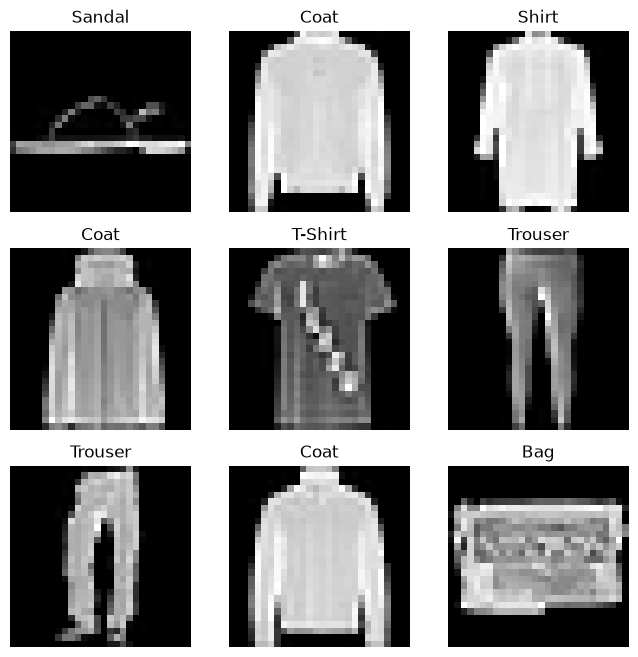

In [5]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8)) #create a figure ,figure size id 8*8 sqaureinches
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()    #torch.randint(low, high, size)    It generates random integers from low (inclusive) to high (exclusive)
    img, label = training_data[sample_idx]  #training_data[sample_idx] equals training_data.__getitem__(sample_idx)
    #Important : training_data(an object essentially) only needs to implement the appropriate special method, such as __getitem__() to be indexed
    figure.add_subplot(rows, cols, i)   #figure.add_subplot(number_of_rows, number_of_columns, position)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")  #Important : PyTorch's "squeeze()" removes dimensions whose size is 1
    #The imshow() function displays an image represented by an array or tensor-like object , and if the Tensors are on GPU ,we need write "plt.imshow(img.squeeze().cpu(), cmap="gray")"
print(img.shape)
plt.show()

## Creating a Custom Dataset for your files

A custom Dataset class must implement three functions: __init__, __len__, and __getitem__. Take a look at this implementation; the FashionMNIST images are stored in a directory `img_dir`, and their labels are stored separately in a CSV file `annotations_file`.

In [ ]:
import pandas as pd
from torchvision.io import decode_image #decode_image() is a function in PyTorch that oads an image file and converts it into a PyTorch tensor,

In [6]:
class CustomImageDataset(Dataset):
    def __init__(self,annotations_file,img_dir,transform=None,target_transform=None):
        self.img_labels=pd.read_csv(annotations_file)
        self.img_dir=img_dir
        self.transform=transform
        self.target_transform=target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self,idx):
        img_path=os.path.join(self.img_dir,self.img_labels.iloc[idx,0])
        image=decode_image(img_path)
        label=self.img_labels.iloc[idx,1]
        if self.transform:
            image=self.transform(image)
        if self.target_transform:
            label=self.target_transform(label)
        return image,label

## Preparing your data for training with DataLoaders

The `Dataset` retrieves our dataset’s features and labels one sample at a time. While training a model, we typically want to pass samples in “minibatches”, reshuffle the data at every epoch to reduce model overfitting, and use Python’s `multiprocessing` to speed up data retrieval.

`DataLoader` is an iterable that abstracts this complexity for us in an easy API.

Here is a illustration of "batch" and "epoch"

<img src="insert_images/batch_epoch.png" alt="Batch Epoch" width="650">

In [7]:
from torch.utils.data import DataLoader

In [ ]:
train_dataloader=DataLoader(training_data,batch_size=64,shuffle=True)   #shuffle=True tells the DataLoader to randomize the order of the training samples when starting a new iteration over the dataset.
test_dataloader=DataLoader(test_data,batch_size=64,shuffle=True)

## Iterate through the DataLoader

Feature batch shape:torch.Size([64, 1, 28, 28])
Labels batch shape:torch.Size([64])


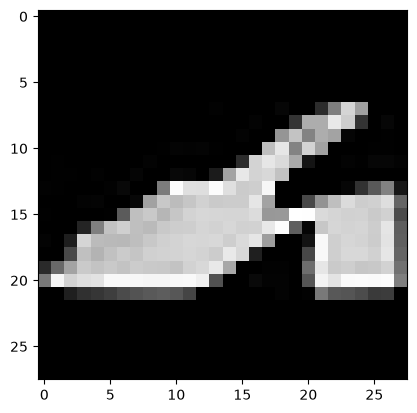

Label:5


In [ ]:
train_features, train_labels=next(iter(train_dataloader))   #x1,x2=next(...) means unpacking the result(a tuple)
#iter() creates an iterator from an iterable object. note: it doesn't iterate itself, it just create an iterator
#next() retrieves the next item from an iterator. note: if there is no next item, Python raise StopIteration
print(f"Feature batch shape:{train_features.size()}")
print(f"Labels batch shape:{train_labels.size()}")
img=train_features[0].squeeze()
label=train_labels[0]
plt.imshow(img,cmap="gray")
plt.show()
print(f"Label:{label}")

In [15]:
#how "batch" changes torch.Size
print(train_features.shape)
print(train_labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])
